# Model 1 — Penalized linear regression (LASSO, Ridge, Elastic net)
**Question:** Which behavioral characteristics best predict 1-year % weight change among U.S. adults who tried to lose weight, beyond demographics and starting BMI? (NHANES Aug 2021–Aug 2023, n = 2,794)

**Design:** each penalty is fitted twice:
- **Covariates only** — 15 demographic predictors + BMI 1 year ago
- **Covariates + behaviors** — the 15 above plus 12 behavioral predictors

The gain from adding behaviors (ΔR², ΔRMSE on the held-out test set, with bootstrap CIs) answers "beyond demographics and starting BMI"; the coefficients answer "which behaviors".

Outcome: `pct_wt_change` = (current − 1 yr ago) ÷ 1 yr ago × 100, restricted to ±50%. Negative = weight lost.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, KFold, RepeatedKFold, cross_validate
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
DATA_PATH = "nhanes_model_ready.csv"   # keep the CSV next to this notebook
OUTCOME = "pct_wt_change"

# NHANES design variables: kept for reference, never used as predictors
ID_COL, WT_COL = "Respondent sequence number", "Full sample 2-year MEC exam weight"
# Set to True to fit and score with the MEC exam weights (population-weighted fit).
# Default False: a standard (unweighted) prediction model, as most ML comparisons do.
USE_SURVEY_WEIGHTS = False

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoCV, RidgeCV, ElasticNetCV, lasso_path

## 1. Load data and define predictor sets
The CSV is already cleaned, but a few predictors still have missing values (notably PHQ-9, drinks/week and income-to-poverty ratio, each ~12%). Rather than drop ~30% of the sample, missing values are handled **inside** the modeling pipeline so nothing leaks from the test set.

In [2]:
df = pd.read_csv(DATA_PATH)

COVARIATES = [
    "age", "female",
    "race_eth_Mexican American", "race_eth_Other Hispanic", "race_eth_NH Black",
    "race_eth_NH Asian", "race_eth_Other/Multiracial",
    "education", "income_poverty_ratio",
    "marital_Widowed/divorced/separated", "marital_Never married",
    "household_size", "us_born", "veteran", "bmi_1yr_ago",
]
BEHAVIORS = [
    "mod_min_wk", "vig_min_wk", "sedentary_hr_day", "phq9_score",
    "drinks_per_week", "sleep_hr_avg",
    "smoking_status_Former", "smoking_status_Current",
    "main_meal_planner", "shares_meal_planning", "main_food_shopper", "shares_food_shopping",
]
FULL = COVARIATES + BEHAVIORS
assert len(COVARIATES) == 15 and len(BEHAVIORS) == 12
assert set(FULL).issubset(df.columns)

print(df.shape)
print(f"Outcome: mean {df[OUTCOME].mean():.2f}%, SD {df[OUTCOME].std():.2f}%, range {df[OUTCOME].min():.1f} to {df[OUTCOME].max():.1f}")
miss = df[FULL].isna().sum()
print("\nPredictors with missing values (handled inside the modeling pipeline):")
print(miss[miss > 0].sort_values(ascending=False).to_frame("n_missing").assign(pct=lambda t: (100 * t.n_missing / len(df)).round(1)))

(2794, 33)
Outcome: mean -1.22%, SD 8.85%, range -40.1 to 50.0

Predictors with missing values (handled inside the modeling pipeline):
                                    n_missing   pct
drinks_per_week                           346  12.4
phq9_score                                333  11.9
income_poverty_ratio                      325  11.6
sleep_hr_avg                               34   1.2
mod_min_wk                                 15   0.5
vig_min_wk                                 15   0.5
bmi_1yr_ago                                11   0.4
sedentary_hr_day                            9   0.3
smoking_status_Former                       2   0.1
smoking_status_Current                      2   0.1
marital_Never married                       1   0.0
marital_Widowed/divorced/separated          1   0.0
shares_meal_planning                        1   0.0
main_food_shopper                           1   0.0


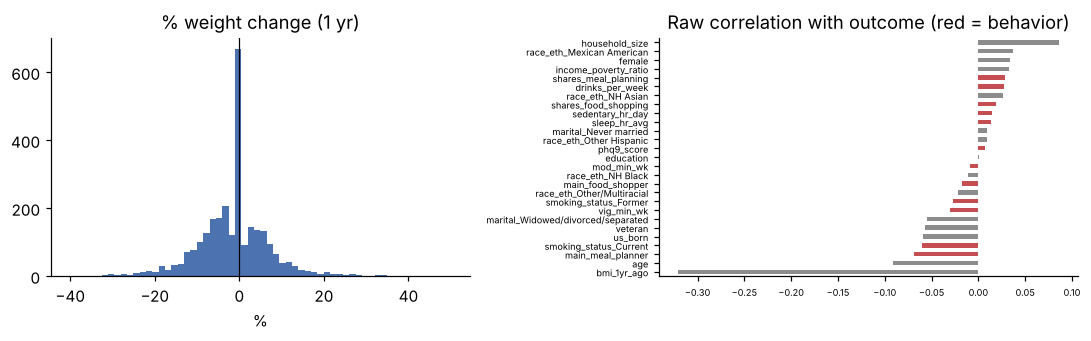

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist(df[OUTCOME], bins=60, color="#4C72B0")
ax[0].axvline(0, color="k", lw=0.8); ax[0].set_title("% weight change (1 yr)"); ax[0].set_xlabel("%")
corr = df[FULL + [OUTCOME]].corr()[OUTCOME].drop(OUTCOME).sort_values()
corr.plot.barh(ax=ax[1], color=["#C44E52" if c in BEHAVIORS else "#8C8C8C" for c in corr.index], fontsize=6)
ax[1].set_title("Raw correlation with outcome (red = behavior)")
plt.tight_layout(); plt.show()

## 2. Train / test split
One held-out test set (20%), stratified on outcome quintiles, with a fixed random seed for reproducibility. All tuning happens with cross-validation on the training set only.

In [4]:
y = df[OUTCOME]
w = df[WT_COL] if USE_SURVEY_WEIGHTS else pd.Series(1.0, index=df.index)

# stratify on outcome quintiles so the heavy tails land in both sets
strata = pd.qcut(y, 5, labels=False, duplicates="drop")
idx_train, idx_test = train_test_split(df.index, test_size=0.20, random_state=RANDOM_STATE, stratify=strata)

y_train, y_test = y.loc[idx_train], y.loc[idx_test]
w_train, w_test = w.loc[idx_train], w.loc[idx_test]
print(f"train n={len(idx_train)}, test n={len(idx_test)}")
print(f"train mean={y_train.mean():.2f}, test mean={y_test.mean():.2f}")

train n=2235, test n=559
train mean=-1.30, test mean=-0.91


In [5]:
def metrics(y_true, y_pred, weights=None):
    return {
        "R2": r2_score(y_true, y_pred, sample_weight=weights),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred, sample_weight=weights)),
        "MAE": mean_absolute_error(y_true, y_pred, sample_weight=weights),
    }

def bootstrap_delta(y_true, pred_a, pred_b, weights=None, n_boot=2000, seed=RANDOM_STATE):
    """Paired bootstrap on the test set: change in R2 and RMSE going from model A to model B."""
    rng = np.random.default_rng(seed)
    y_true, pred_a, pred_b = map(np.asarray, (y_true, pred_a, pred_b))
    wts = np.ones_like(y_true) if weights is None else np.asarray(weights)
    d_r2, d_rmse = [], []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_true), len(y_true))
        ma, mb = metrics(y_true[i], pred_a[i], wts[i]), metrics(y_true[i], pred_b[i], wts[i])
        d_r2.append(mb["R2"] - ma["R2"]); d_rmse.append(mb["RMSE"] - ma["RMSE"])
    out = {}
    for name, arr in [("dR2", np.array(d_r2)), ("dRMSE", np.array(d_rmse))]:
        out[name] = (arr.mean(), *np.percentile(arr, [2.5, 97.5]))
    return out

TEST_W = w_test.values if USE_SURVEY_WEIGHTS else None
FIT_W = w_train.values if USE_SURVEY_WEIGHTS else None

In [6]:
# Reference point: predict the training mean for everyone
baseline_pred = np.full(len(y_test), np.average(y_train, weights=w_train))
pd.DataFrame([metrics(y_test, baseline_pred, TEST_W)], index=["Mean-only baseline"]).round(3)

,R2,RMSE,MAE
Mean-only baseline,-0.002,9.089,6.28


## 3. Pipeline and models
Each pipeline: **median imputation** (plus a missing-value indicator for income, PHQ-9 and drinks/week, the three ~12%-missing predictors) → **standardization** → penalized regression. Standardizing puts every coefficient on the same scale (change in % weight per 1 SD of the predictor), which is what lets us rank predictors.

The penalty strength (and the L1/L2 mix for elastic net) is chosen by 10-fold CV within the training set.

In [7]:
CV = KFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

# Missing-value indicators only for the three predictors with substantial (~12%) missingness;
# for the rest (<1.5% missing) an indicator would be fitted on a handful of rows and add noise.
FLAG_MISSING = ["income_poverty_ratio", "phq9_score", "drinks_per_week"]

def make_pipe(estimator, cols):
    flag = [c for c in FLAG_MISSING if c in cols]
    rest = [c for c in cols if c not in flag]
    pre = ColumnTransformer([
        ("flagged", SimpleImputer(strategy="median", add_indicator=True), flag),
        ("other", SimpleImputer(strategy="median"), rest),
    ], verbose_feature_names_out=False)
    return Pipeline([
        ("impute", pre),
        ("scale", StandardScaler()),
        ("model", estimator),
    ])

ESTIMATORS = {
    "LASSO": lambda: LassoCV(cv=CV, alphas=np.logspace(-4, 1, 100), max_iter=50_000, random_state=RANDOM_STATE),
    "Ridge": lambda: RidgeCV(alphas=np.logspace(-3, 4, 100)),   # efficient leave-one-out CV
    "Elastic net": lambda: ElasticNetCV(cv=CV, l1_ratio=[.1, .3, .5, .7, .9, .95, .99],
                                        alphas=np.logspace(-4, 1, 100), max_iter=50_000, random_state=RANDOM_STATE),
}
FEATURE_SETS = {"Covariates": COVARIATES, "Covariates + behaviors": FULL}

fitted, preds, rows = {}, {}, []
for m_name, make_est in ESTIMATORS.items():
    for s_name, cols in FEATURE_SETS.items():
        pipe = make_pipe(make_est(), cols)
        pipe.fit(df.loc[idx_train, cols], y_train, model__sample_weight=FIT_W)
        p = pipe.predict(df.loc[idx_test, cols])
        fitted[(m_name, s_name)], preds[(m_name, s_name)] = pipe, p
        est = pipe.named_steps["model"]
        rows.append({"Model": m_name, "Predictors": s_name,
                     "alpha": est.alpha_, "l1_ratio": getattr(est, "l1_ratio_", np.nan),
                     "n_nonzero": int(np.sum(np.abs(est.coef_) > 1e-8)), "n_features": est.coef_.size,
                     **metrics(y_test, p, TEST_W)})

results = pd.DataFrame(rows).set_index(["Model", "Predictors"])
results.round(4)

alpha  l1_ratio  n_nonzero  n_features      R2    RMSE     MAE
Model       Predictors                                                                               
LASSO       Covariates                0.1205       NaN         11          16  0.0744  8.7364  6.0481
            Covariates + behaviors    0.0955       NaN         20          30  0.0795  8.7127  6.0521
Ridge       Covariates              123.2847       NaN         16          16  0.0715  8.7501  6.0508
            Covariates + behaviors  170.7353       NaN         30          30  0.0790  8.7150  6.0484
Elastic net Covariates                0.1205      0.99         11          16  0.0745  8.7362  6.0478
            Covariates + behaviors    0.0955      0.99         20          30  0.0795  8.7127  6.0520

## 4. Do behaviors add predictive value?
**Test set:** paired bootstrap of the change in R² and RMSE (covariates → covariates + behaviors). A CI for ΔR² that excludes 0 indicates behaviors add predictive information.

**Repeated CV on training data:** a second, less split-dependent estimate (5-fold × 5 repeats) of the same comparison.

In [8]:
rows = []
for m_name in ESTIMATORS:
    d = bootstrap_delta(y_test, preds[(m_name, "Covariates")], preds[(m_name, "Covariates + behaviors")], TEST_W)
    rows.append({"Model": m_name,
                 "ΔR² (test)": d["dR2"][0], "ΔR² 95% CI": f"[{d['dR2'][1]:.3f}, {d['dR2'][2]:.3f}]",
                 "ΔRMSE (test)": d["dRMSE"][0], "ΔRMSE 95% CI": f"[{d['dRMSE'][1]:.3f}, {d['dRMSE'][2]:.3f}]"})
delta_test = pd.DataFrame(rows).set_index("Model")
delta_test.round(4)

,ΔR² (test),ΔR² 95% CI,ΔRMSE (test),ΔRMSE 95% CI
Model,,,,
LASSO,0.0051,"[-0.010, 0.021]",-0.0242,"[-0.095, 0.047]"
Ridge,0.0077,"[-0.011, 0.028]",-0.0359,"[-0.127, 0.054]"
Elastic net,0.0051,"[-0.010, 0.021]",-0.0241,"[-0.095, 0.047]"


In [9]:
rcv = RepeatedKFold(n_splits=5, n_repeats=5, random_state=RANDOM_STATE)
cv_rows = []
for m_name, make_est in ESTIMATORS.items():
    scores = {}
    for s_name, cols in FEATURE_SETS.items():
        r = cross_validate(make_pipe(make_est(), cols), df.loc[idx_train, cols], y_train, cv=rcv,
                           scoring=["r2", "neg_root_mean_squared_error"],
                           params={"model__sample_weight": FIT_W} if USE_SURVEY_WEIGHTS else None)
        scores[s_name] = r
        cv_rows.append({"Model": m_name, "Predictors": s_name,
                        "CV R2 mean": r["test_r2"].mean(), "CV R2 SD": r["test_r2"].std(),
                        "CV RMSE mean": -r["test_neg_root_mean_squared_error"].mean()})
    diff = scores["Covariates + behaviors"]["test_r2"] - scores["Covariates"]["test_r2"]
    cv_rows[-1]["ΔR² vs covariates (folds where better)"] = f"{diff.mean():.4f} ({(diff > 0).sum()}/{len(diff)})"
cv_results = pd.DataFrame(cv_rows).set_index(["Model", "Predictors"])
cv_results.round(4)

CV R2 mean  CV R2 SD  CV RMSE mean ΔR² vs covariates (folds where better)
Model       Predictors                                                                                       
LASSO       Covariates                  0.1176    0.0287        8.2331                                    NaN
            Covariates + behaviors      0.1253    0.0276        8.1968                         0.0077 (20/25)
Ridge       Covariates                  0.1156    0.0298        8.2423                                    NaN
            Covariates + behaviors      0.1231    0.0280        8.2071                         0.0075 (20/25)
Elastic net Covariates                  0.1174    0.0285        8.2339                                    NaN
            Covariates + behaviors      0.1249    0.0275        8.1989                         0.0075 (21/25)

## 5. Which behaviors matter? (standardized coefficients)
Coefficients are per 1 SD of the predictor, in percentage points of weight change. **Negative = associated with more weight loss.** LASSO / elastic net set unhelpful predictors exactly to zero, which is itself a selection result. Missing-indicator columns (`missingindicator_*`) are shown too: a non-zero one means that *not answering* that question is itself predictive.

In [10]:
def coef_table(pipe):
    names = pipe.named_steps["impute"].get_feature_names_out()
    return pd.Series(pipe.named_steps["model"].coef_, index=names)

coefs = pd.DataFrame({m: coef_table(fitted[(m, "Covariates + behaviors")]) for m in ESTIMATORS})
coefs["group"] = ["Behavior" if c.replace("missingindicator_", "") in BEHAVIORS else "Covariate" for c in coefs.index]
coefs = coefs.reindex(coefs["Elastic net"].abs().sort_values(ascending=False).index)
coefs.round(3)

,LASSO,Ridge,Elastic net,group
bmi_1yr_ago,-3.010,-2.911,-3.008,Covariate
age,-0.496,-0.504,-0.496,Covariate
main_meal_planner,-0.465,-0.602,-0.466,Behavior
missingindicator_drinks_per_week,0.371,0.482,0.371,Behavior
household_size,0.365,0.450,0.365,Covariate
smoking_status_Current,-0.351,-0.457,-0.352,Behavior
veteran,-0.343,-0.393,-0.344,Covariate
vig_min_wk,-0.316,-0.356,-0.317,Behavior
education,-0.303,-0.391,-0.303,Covariate
sedentary_hr_day,0.245,0.289,0.245,Behavior


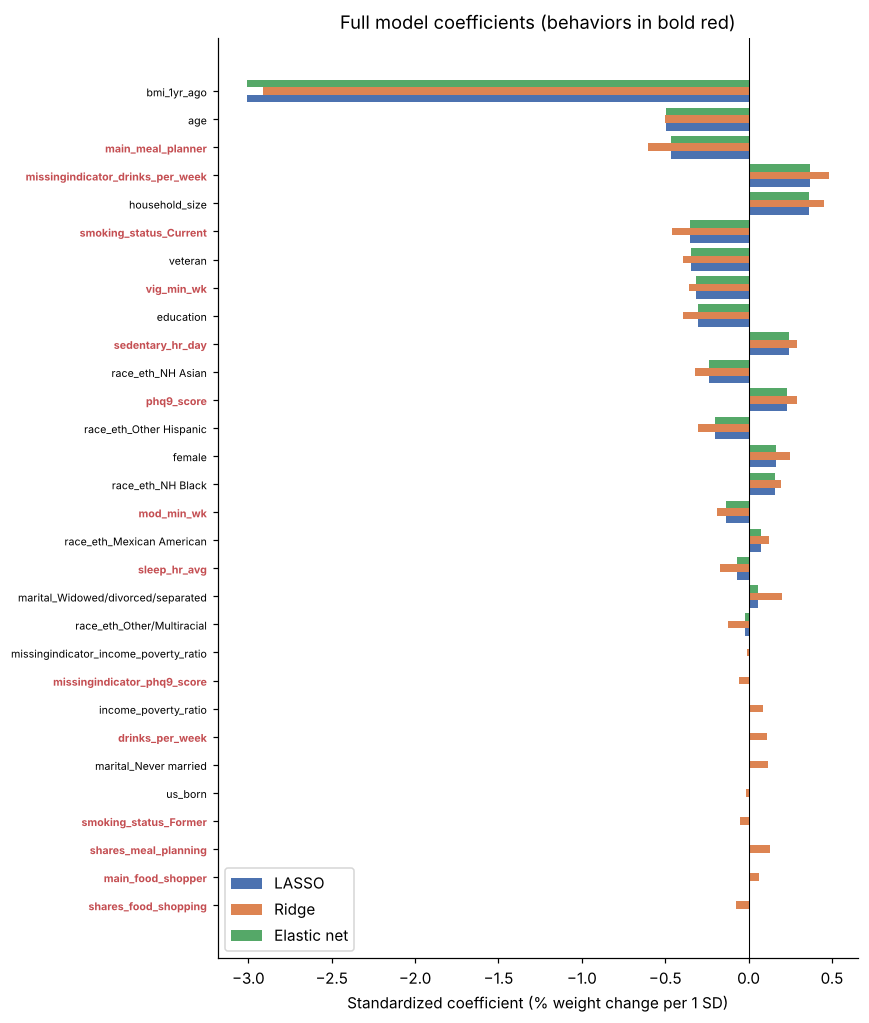

In [11]:
plot_df = coefs.drop(columns="group").iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 0.28 * len(plot_df) + 1))
yy = np.arange(len(plot_df)); h = 0.27
for k, (m, col) in enumerate(zip(ESTIMATORS, ["#4C72B0", "#DD8452", "#55A868"])):
    ax.barh(yy + (k - 1) * h, plot_df[m], height=h, label=m, color=col)
ax.set_yticks(yy); ax.set_yticklabels(plot_df.index, fontsize=7)
for lab in ax.get_yticklabels():
    if lab.get_text().replace("missingindicator_", "") in BEHAVIORS: lab.set_color("#C44E52"); lab.set_fontweight("bold")
ax.axvline(0, color="k", lw=0.7); ax.set_xlabel("Standardized coefficient (% weight change per 1 SD)")
ax.set_title("Full model coefficients (behaviors in bold red)"); ax.legend()
plt.tight_layout(); plt.show()

### LASSO path
Order in which predictors enter as the penalty relaxes. Predictors entering early carry the strongest unique signal. The dashed line is the CV-chosen penalty.

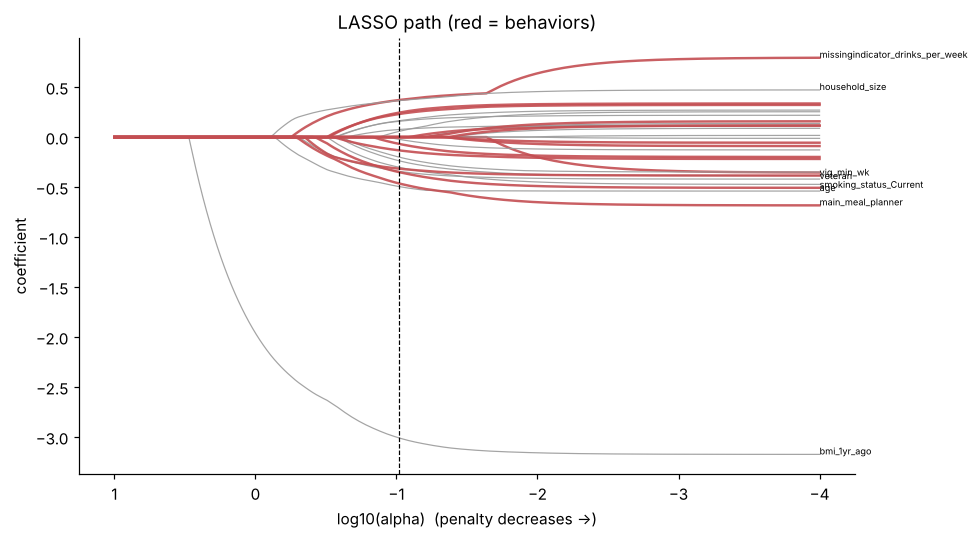

Order of entry (first 15):
['bmi_1yr_ago', 'household_size', 'age', 'missingindicator_drinks_per_week', 'main_meal_planner', 'veteran', 'vig_min_wk', 'smoking_status_Current', 'education', 'sedentary_hr_day', 'phq9_score', 'mod_min_wk', 'female', 'race_eth_NH Black', 'race_eth_NH Asian']


In [12]:
pipe = fitted[("LASSO", "Covariates + behaviors")]
Xs = pipe[:-1].transform(df.loc[idx_train, FULL])
names = pipe.named_steps["impute"].get_feature_names_out()
alphas, path, _ = lasso_path(Xs, y_train.values - y_train.mean(), alphas=np.logspace(-4, 1, 200), max_iter=50_000)

fig, ax = plt.subplots(figsize=(9, 5))
entry = {}
for j, n in enumerate(names):
    nz = np.nonzero(np.abs(path[j]) > 1e-8)[0]
    entry[n] = alphas[nz[0]] if len(nz) else 0
    beh = n.replace("missingindicator_", "") in BEHAVIORS
    ax.plot(np.log10(alphas), path[j], lw=1.6 if beh else 0.8, color="#C44E52" if beh else "#9A9A9A", alpha=0.9)
for n in sorted(entry, key=entry.get, reverse=True)[:8]:
    j = list(names).index(n); ax.annotate(n, (np.log10(alphas[-1]), path[j, -1]), fontsize=6)
ax.axvline(np.log10(pipe.named_steps["model"].alpha_), ls="--", color="k", lw=0.8)
ax.invert_xaxis(); ax.set_xlabel("log10(alpha)  (penalty decreases →)"); ax.set_ylabel("coefficient")
ax.set_title("LASSO path (red = behaviors)"); plt.tight_layout(); plt.show()

print("Order of entry (first 15):")
print(pd.Series(entry).sort_values(ascending=False).head(15).index.tolist())

### Selection stability (bootstrap LASSO)
A single LASSO fit can pick one of two correlated predictors somewhat arbitrarily. Refitting on 200 bootstrap resamples of the training set (at the CV-chosen penalty) shows how often each predictor is selected and how stable its sign is. Predictors selected in most resamples, with a consistent sign, are the robust findings.

In [13]:
from sklearn.linear_model import Lasso
alpha_star = fitted[("LASSO", "Covariates + behaviors")].named_steps["model"].alpha_
rng = np.random.default_rng(RANDOM_STATE)
B, boot = 200, []
Xtr, ytr = df.loc[idx_train, FULL].reset_index(drop=True), y_train.reset_index(drop=True)
for b in range(B):
    i = rng.integers(0, len(Xtr), len(Xtr))
    p = make_pipe(Lasso(alpha=alpha_star, max_iter=50_000), FULL).fit(Xtr.iloc[i], ytr.iloc[i])
    boot.append(coef_table(p))
boot = pd.DataFrame(boot).fillna(0)

stability = pd.DataFrame({
    "selected_%": 100 * (boot.abs() > 1e-8).mean(),
    "median_coef": boot.median(),
    "%_negative_when_selected": 100 * (boot < 0).sum() / (boot.abs() > 1e-8).sum().replace(0, np.nan),
})
stability["group"] = ["Behavior" if c.replace("missingindicator_", "") in BEHAVIORS else "Covariate" for c in stability.index]
stability.sort_values("selected_%", ascending=False).round(1)

,selected_%,median_coef,%_negative_when_selected,group
main_meal_planner,100.0,-0.4,100.0,Behavior
bmi_1yr_ago,100.0,-3.0,100.0,Covariate
age,99.5,-0.5,100.0,Covariate
smoking_status_Current,98.0,-0.4,99.0,Behavior
veteran,97.5,-0.3,100.0,Covariate
household_size,97.0,0.4,0.0,Covariate
vig_min_wk,93.0,-0.3,100.0,Behavior
education,93.0,-0.3,98.4,Covariate
race_eth_NH Asian,92.0,-0.2,100.0,Covariate
sedentary_hr_day,92.0,0.2,1.1,Behavior


## 6. Residual check

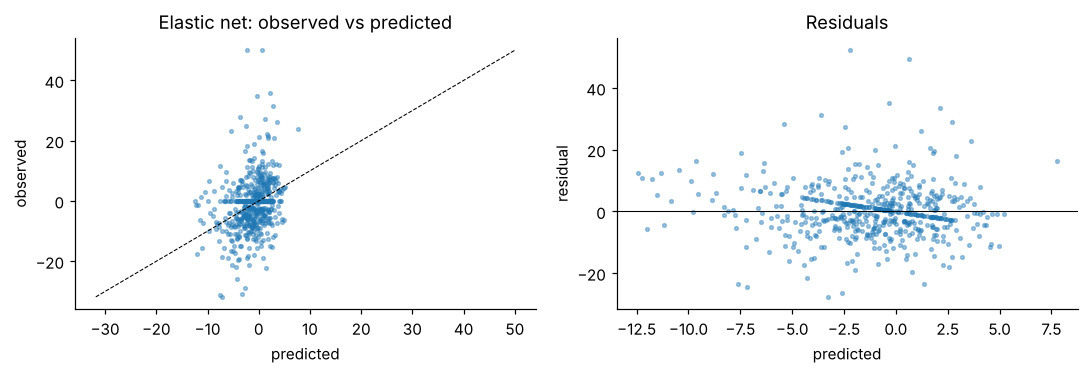

In [14]:
best = results.xs("Covariates + behaviors", level="Predictors")["R2"].idxmax()
p = preds[(best, "Covariates + behaviors")]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].scatter(p, y_test, s=6, alpha=0.4); lim = [y_test.min(), y_test.max()]
ax[0].plot(lim, lim, "k--", lw=0.7); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("observed"); ax[0].set_title(f"{best}: observed vs predicted")
ax[1].scatter(p, y_test - p, s=6, alpha=0.4); ax[1].axhline(0, color="k", lw=0.7)
ax[1].set_xlabel("predicted"); ax[1].set_ylabel("residual"); ax[1].set_title("Residuals")
plt.tight_layout(); plt.show()

## 7. Summary table
Final test-set results for all three penalized models, saved to `model1_results.csv` along with the coefficients and LASSO stability tables.

In [15]:
summary = results[["R2", "RMSE", "MAE", "n_nonzero"]].join(
    delta_test[["ΔR² (test)", "ΔR² 95% CI"]], on="Model")
summary.loc[summary.index.get_level_values("Predictors") == "Covariates", ["ΔR² (test)", "ΔR² 95% CI"]] = np.nan
summary.to_csv("model1_results.csv")
stability.to_csv("model1_lasso_stability.csv")
coefs.to_csv("model1_coefficients.csv")
summary.round(4)

R2    RMSE     MAE  n_nonzero  ΔR² (test)       ΔR² 95% CI
Model       Predictors                                                                            
LASSO       Covariates              0.0744  8.7364  6.0481         11         NaN              NaN
            Covariates + behaviors  0.0795  8.7127  6.0521         20      0.0051  [-0.010, 0.021]
Ridge       Covariates              0.0715  8.7501  6.0508         16         NaN              NaN
            Covariates + behaviors  0.0790  8.7150  6.0484         30      0.0077  [-0.011, 0.028]
Elastic net Covariates              0.0745  8.7362  6.0478         11         NaN              NaN
            Covariates + behaviors  0.0795  8.7127  6.0520         20      0.0051  [-0.010, 0.021]

## Interpretation notes
- **ΔR²** is the headline answer to "beyond demographics and starting BMI". Self-reported 1-year weight change is noisy, so low absolute R² is expected; the question is whether behaviors add a reliable increment.
- **Coefficients are associations, not effects.** Cross-sectional NHANES data: e.g., depressive symptoms or sleep may be consequences as well as causes of weight change.
- Behaviors were measured at the exam, i.e. at the *end* of the weight-change window, which limits temporal interpretation.
- Set `USE_SURVEY_WEIGHTS = True` at the top to fit and evaluate with MEC exam weights, if you want population-weighted estimates. (Weighted fitting is not a full design-based analysis; strata/PSU are not used for variance.)